# 06 — Vieses e ética

Avaliação do classificador por sexo, faixa etária e estado civil. As previsões vêm do Notebook 03; não há novo treinamento aqui.

Os resultados descrevem diferenças observadas nesta amostra histórica. Não representam uma auditoria completa de justiça algorítmica.

In [8]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import average_precision_score, roc_auc_score

sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

ORIGEM = ROOT / "data" / "processed" / "predicoes_teste.csv"
DESTINO = ROOT / "reports" / "vieses"
FIGURAS = ROOT / "reports" / "figures"
DESTINO.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

if not ORIGEM.exists():
    raise FileNotFoundError("Execute o Notebook 03 para gerar data/processed/predicoes_teste.csv")

df = pd.read_csv(ORIGEM)
obrigatorias = {"SEX", "AGE", "MARRIAGE", "inadimplente", "probabilidade", "predito"}
assert obrigatorias.issubset(df.columns), f"Faltam: {obrigatorias - set(df.columns)}"
assert df["inadimplente"].isin([0, 1]).all()
assert df["predito"].isin([0, 1]).all()
assert df["probabilidade"].between(0, 1).all()
assert df[list(obrigatorias)].notna().all().all()

print("Registros de teste:", len(df))
print("Taxa de inadimplência:", f"{df['inadimplente'].mean():.2%}")
print("Colunas:", df.columns.tolist())

Registros de teste: 6000
Taxa de inadimplência: 22.12%
Colunas: ['row_id', 'SEX', 'AGE', 'EDUCATION', 'MARRIAGE', 'inadimplente', 'probabilidade', 'predito']


As previsões e o limiar são os mesmos definidos no Notebook 03. Esse arquivo contém apenas o conjunto de teste, não a base inteira.

In [9]:
# Rótulos conforme a documentação original da UCI.
# Códigos sem definição ficam identificados como tal.
df["sexo_grupo"] = df["SEX"].map({1: "Masculino", 2: "Feminino"}).fillna("Não informado")
df["estado_civil_grupo"] = df["MARRIAGE"].map({
    1: "Casado(a)", 2: "Solteiro(a)", 3: "Outro", 0: "Não especificado"
}).fillna("Não informado")
df["faixa_etaria"] = pd.cut(
    df["AGE"], bins=[-np.inf, 29, 39, 49, 59, np.inf],
    labels=["Até 29", "30–39", "40–49", "50–59", "60+"]
)

for coluna in ["sexo_grupo", "faixa_etaria", "estado_civil_grupo"]:
    print(f"\n{coluna}:")
    print(df[coluna].value_counts(dropna=False).to_string())


sexo_grupo:
sexo_grupo
Feminino     3700
Masculino    2300

faixa_etaria:
faixa_etaria
30–39     2227
Até 29    1958
40–49     1284
50–59      457
60+         74

estado_civil_grupo:
estado_civil_grupo
Solteiro(a)         3216
Casado(a)           2713
Outro                 64
Não especificado       7


As faixas de idade são usadas só para facilitar a comparação. Códigos desconhecidos não são tratados como dados ausentes automaticamente.

In [10]:
def metricas_por_grupo(dados, coluna):
    linhas = []
    for grupo, fatia in dados.groupby(coluna, observed=True, dropna=False):
        real = fatia["inadimplente"].to_numpy()
        previsto = fatia["predito"].to_numpy()
        tp = int(((real == 1) & (previsto == 1)).sum())
        fp = int(((real == 0) & (previsto == 1)).sum())
        tn = int(((real == 0) & (previsto == 0)).sum())
        fn = int(((real == 1) & (previsto == 0)).sum())
        precision = tp / (tp + fp) if tp + fp else np.nan
        recall = tp / (tp + fn) if tp + fn else np.nan
        fpr = fp / (fp + tn) if fp + tn else np.nan
        f1 = 2 * precision * recall / (precision + recall) if (pd.notna(precision) and pd.notna(recall) and precision + recall) else np.nan
        linhas.append({
            "variavel": coluna, "grupo": str(grupo), "clientes": len(fatia),
            "inadimplentes": int(real.sum()), "adimplentes": int((real == 0).sum()),
            "taxa_inadimplencia": real.mean(), "taxa_alertas": previsto.mean(),
            "precision": precision, "recall": recall, "F1": f1,
            "FPR": fpr, "TP": tp, "FP": fp, "TN": tn, "FN": fn
        })
    return pd.DataFrame(linhas)

colunas_grupo = ["sexo_grupo", "faixa_etaria", "estado_civil_grupo"]
metricas = pd.concat([metricas_por_grupo(df, col) for col in colunas_grupo], ignore_index=True)
display(metricas[["variavel", "grupo", "clientes", "inadimplentes", "taxa_inadimplencia", "precision", "recall", "F1", "FPR"]].round(3))

,variavel,grupo,clientes,inadimplentes,taxa_inadimplencia,precision,recall,F1,FPR
0,sexo_grupo,Feminino,3700,749,0.202,0.269,0.870,0.411,0.600
1,sexo_grupo,Masculino,2300,578,0.251,0.333,0.900,0.486,0.604
2,faixa_etaria,Até 29,1958,426,0.218,0.278,0.901,0.425,0.649
3,faixa_etaria,30–39,2227,450,0.202,0.280,0.862,0.423,0.560
4,faixa_etaria,40–49,1284,308,0.240,0.323,0.896,0.475,0.592
5,faixa_etaria,50–59,457,120,0.263,0.333,0.883,0.484,0.629
6,faixa_etaria,60+,74,23,0.311,0.367,0.783,0.500,0.608
7,estado_civil_grupo,Casado(a),2713,641,0.236,0.314,0.874,0.462,0.589
8,estado_civil_grupo,Não especificado,7,0,0.000,0.000,NaN,NaN,0.857
9,estado_civil_grupo,Outro,64,15,0.234,0.255,0.867,0.394,0.776


Recall mede a proporção de inadimplentes corretamente identificados. FPR mede alertas incorretos entre os adimplentes. As comparações devem considerar também o tamanho de cada grupo: taxas de grupos pequenos podem variar bastante.

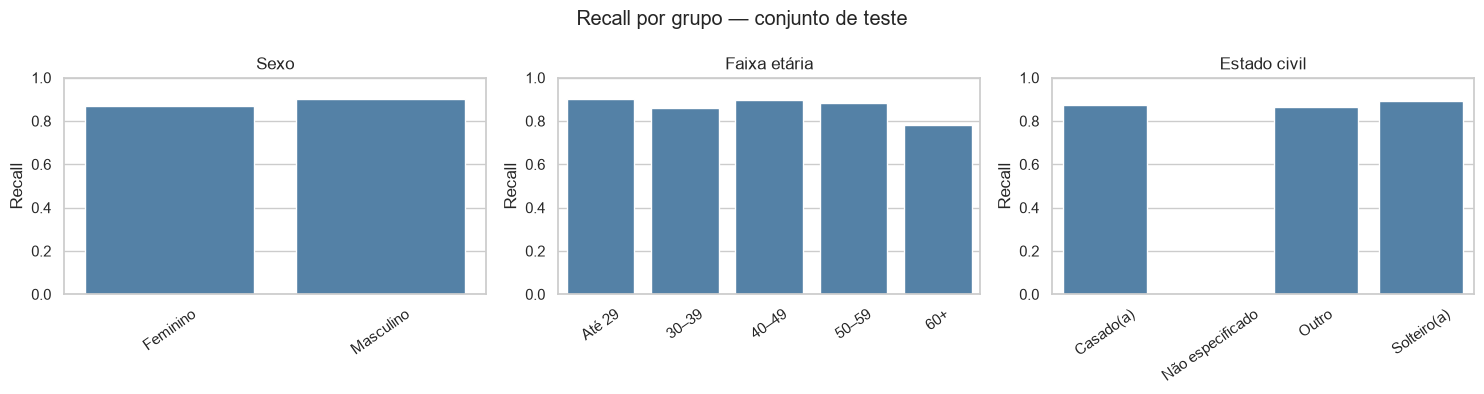

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, coluna, titulo in zip(
    axes, colunas_grupo, ["Sexo", "Faixa etária", "Estado civil"]
):
    base = metricas[metricas["variavel"] == coluna]
    sns.barplot(data=base, x="grupo", y="recall", color="steelblue", ax=ax)
    ax.set(title=titulo, xlabel="", ylabel="Recall", ylim=(0, 1))
    ax.tick_params(axis="x", rotation=35)

plt.suptitle("Recall por grupo — conjunto de teste")
plt.tight_layout()
plt.savefig(FIGURAS / "06_recall_grupos.png", dpi=140, bbox_inches="tight")
plt.show()

Diferenças de recall são sinais para investigação, não prova automática de discriminação. Também é importante observar a taxa de inadimplência e o número de casos positivos em cada grupo.

In [12]:
# Comparação descritiva, sem testes de significância entre múltiplos grupos.
comparacao = []
for coluna in colunas_grupo:
    base = metricas.loc[metricas["variavel"] == coluna]
    base = base.loc[base["inadimplentes"] >= 30].copy()
    if len(base) < 2:
        comparacao.append({"variavel": coluna, "grupos_com_30_positivos": len(base), "amplitude_recall": np.nan, "amplitude_FPR": np.nan})
        continue
    comparacao.append({
        "variavel": coluna,
        "grupos_com_30_positivos": len(base),
        "amplitude_recall": base["recall"].max() - base["recall"].min(),
        "amplitude_FPR": base["FPR"].max() - base["FPR"].min(),
    })

comparacao = pd.DataFrame(comparacao)
display(comparacao.round(3))

,variavel,grupos_com_30_positivos,amplitude_recall,amplitude_FPR
0,sexo_grupo,2,0.029,0.003
1,faixa_etaria,4,0.039,0.089
2,estado_civil_grupo,2,0.019,0.019


A amplitude é a diferença entre a maior e a menor taxa observada. O mínimo de 30 inadimplentes por grupo é um filtro exploratório, não um critério estatístico de garantia. Grupos menores continuam na tabela completa.

In [13]:
# Verificação geral para comparar com o resumo por grupos.
real = df["inadimplente"].to_numpy()
pred = df["predito"].to_numpy()
tp = ((real == 1) & (pred == 1)).sum()
fp = ((real == 0) & (pred == 1)).sum()
tn = ((real == 0) & (pred == 0)).sum()
fn = ((real == 1) & (pred == 0)).sum()

resumo_geral = {
    "clientes": int(len(df)),
    "inadimplentes": int(real.sum()),
    "precision": float(tp / (tp + fp)) if tp + fp else None,
    "recall": float(tp / (tp + fn)) if tp + fn else None,
    "FPR": float(fp / (fp + tn)) if fp + tn else None,
    "PR_AUC": float(average_precision_score(real, df["probabilidade"])),
    "ROC_AUC": float(roc_auc_score(real, df["probabilidade"]))
}
print(pd.Series(resumo_geral).round(3))

clientes         6000.000
inadimplentes    1327.000
precision           0.294
recall              0.883
FPR                 0.602
PR_AUC              0.537
ROC_AUC             0.775
dtype: float64


O modelo usa dados financeiros e de pagamentos; sexo, idade e estado civil não entraram diretamente como preditores no Notebook 03. Isso não impede disparidades: outras variáveis podem estar relacionadas a características demográficas.

In [14]:
metricas.to_csv(DESTINO / "metricas_por_grupo.csv", index=False)
comparacao.to_csv(DESTINO / "comparacao_grupos.csv", index=False)
(DESTINO / "resumo_geral.json").write_text(
    json.dumps(resumo_geral, indent=2, ensure_ascii=False), encoding="utf-8"
)
print("Resultados salvos em", DESTINO)

Resultados salvos em d:\projetos\credit-risk-segmentation\reports\vieses


## Privacidade, limites e uso dos dados

- **Origem:** base pública da UCI, com registros históricos de Taiwan (2005). Não representa a população atual de cooperativas de crédito brasileiras.
- **Identificadores:** o identificador do cliente não foi utilizado no treinamento. Evitamos exportar identificadores diretos nos relatórios.
- **Finalidade:** demonstração acadêmica de análise de risco; os resultados não devem ser usados para negar crédito ou tomar decisões reais sobre pessoas.
- **Variáveis demográficas:** não entram no classificador atual. Foram usadas nesta auditoria para observar possíveis diferenças de desempenho.
- **Limitações:** medidas por grupo não identificam todas as formas de viés; podem existir fatores de confusão, diferenças na prevalência e instabilidade em grupos pequenos. O dataset histórico não permite verificar efeitos em produção.
- **LGPD:** o uso de dados reais no Brasil exigiria avaliação da base legal, finalidade, necessidade, segurança, transparência e direitos dos titulares. Este notebook não constitui avaliação jurídica nem comprova conformidade.

## Conclusão

No conjunto de teste (6.000 clientes), o modelo apresentou recall de **88,3%**, precision de **29,4%** e FPR de **60,2%**. O limiar escolhido prioriza a identificação de inadimplentes, mas produz muitos alertas incorretos entre clientes adimplentes.

Por sexo, o recall foi de **87,0% no grupo feminino** e **90,0% no masculino**; o FPR ficou próximo de 60% nos dois grupos. Nas faixas etárias com ao menos 30 inadimplentes, a diferença máxima de recall foi de **3,9 pontos percentuais**, e a de FPR foi de **8,9 pontos percentuais**. Para estado civil, considerando somente os grupos com ao menos 30 inadimplentes, essas diferenças foram de **1,9 ponto percentual** em cada métrica.

O grupo de **60 anos ou mais** tem apenas 74 clientes, dos quais 23 inadimplentes. O grupo de estado civil **não especificado** tem 7 clientes e nenhum inadimplente; por isso, não é possível calcular recall nesse último grupo. Essas amostras são insuficientes para conclusões firmes sobre disparidades.

As diferenças são descritivas e não demonstram discriminação nem ausência de viés. Como a base é histórica e de outro contexto geográfico, os resultados servem apenas para análise exploratória. Antes de qualquer aplicação real, seriam necessárias avaliações mais amplas de desempenho, representatividade, governança e conformidade legal.
